# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import meshio
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

# import model

In [2]:
model = PhysicsInformedNN(lb, ub, output_dim=4, num_hidden_layers=8, num_neurons_per_layer=256, activation='tanh')
model.build(input_shape=(None,3))
model.load_weights(WEIGHT_PATH+'weights1.h5')

# Check results

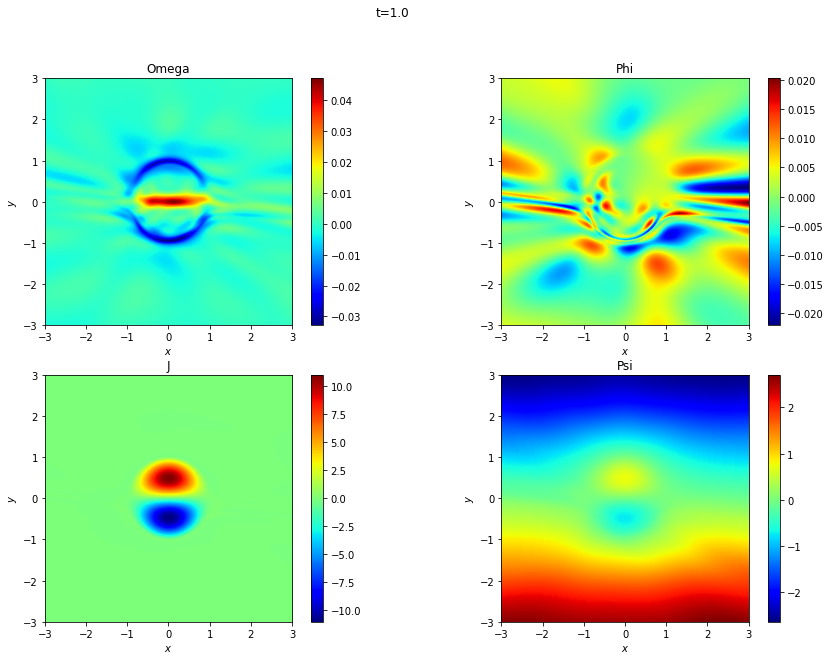

In [7]:
N = 500
t = 1.

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
u = model(tf.cast(Xgrid,DTYPE))

omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(omega, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('t={}'.format(t))
plt.show()

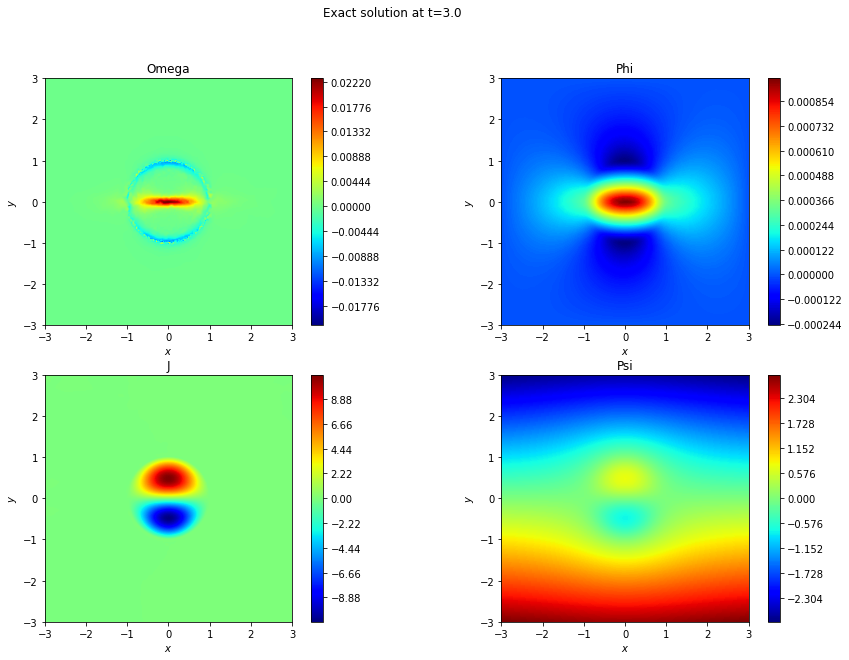

In [11]:
plot_exact_solution(300)


                    phi_0_omega  8.0064e-02
                    phi_0_phi    2.5785e-04
                    phi_0_J      2.9399e-01
                    phi_0_psi    9.4103e-03


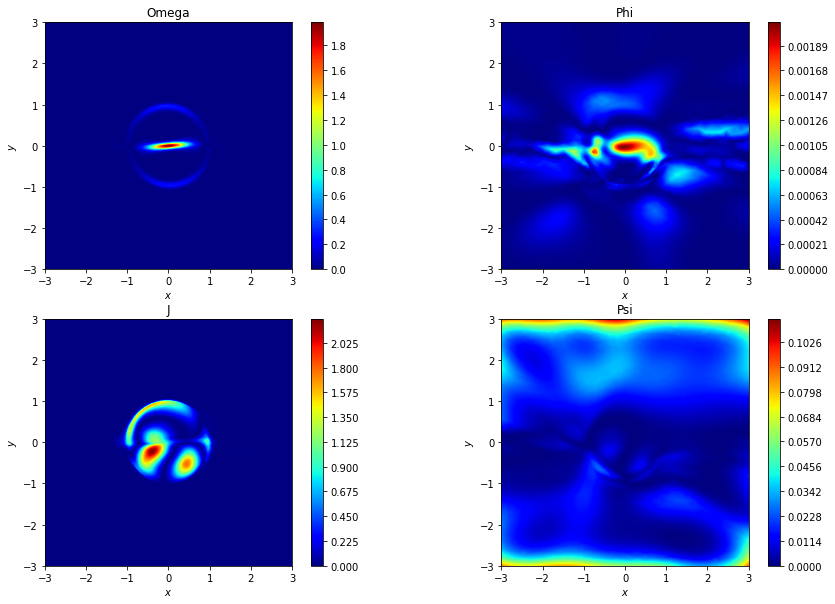

In [18]:
t = 600

# load exact solution
reader = meshio.read(DATA_PATH+'tiltC'+str(t)+'.vtk')
x = reader.points
triangles =  reader.cells_dict['triangle']
J = reader.point_data['current']
reader = meshio.read(DATA_PATH+'tiltO'+str(t)+'.vtk')
omega = reader.point_data['vorticity']
reader = meshio.read(DATA_PATH+'tiltphi'+str(t)+'.vtk')
phi = reader.point_data['stream']
reader = meshio.read(DATA_PATH+'tiltpsi'+str(t)+'.vtk')
psi = reader.point_data['champ']

my_t = (t-300)/100
X_data = tf.concat([my_t*tf.ones((len(x),1), dtype=DTYPE), x[:,0:1], x[:,1:2]], axis=1)
u_data = np.vstack((omega, phi, J, psi)).T
u_data = tf.cast(u_data, DTYPE)

# Compute phi_0
u_pred = model(X_data)

omega_error = tf.square(u_data[:,0:1] - u_pred[:,0:1])
phi_error = tf.square(u_data[:,1:2] - u_pred[:,1:2])
J_error = tf.square(u_data[:,2:3] - u_pred[:,2:3])
psi_error = tf.square(u_data[:,3:4] - u_pred[:,3:4])

phi_0_omega = tf.reduce_mean(omega_error)
phi_0_phi = tf.reduce_mean(phi_error)
phi_0_J = tf.reduce_mean(J_error)
phi_0_psi = tf.reduce_mean(psi_error)

print('''
                    phi_0_omega  {:6.4e}
                    phi_0_phi    {:6.4e}
                    phi_0_J      {:6.4e}
                    phi_0_psi    {:6.4e}\n'''.format(phi_0_omega, phi_0_phi,phi_0_J, phi_0_psi), end="")

# plot
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].tricontourf(x[:,0], x[:,1], triangles, tf.reshape(omega_error,-1), 800, cmap='jet');
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].tricontourf(x[:,0], x[:,1], triangles,  tf.reshape(phi_error,-1), 800, cmap='jet');
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].tricontourf(x[:,0], x[:,1], triangles,  tf.reshape(J_error,-1), 800, cmap='jet');
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].tricontourf(x[:,0], x[:,1], triangles,  tf.reshape(psi_error,-1), 800, cmap='jet');
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi');

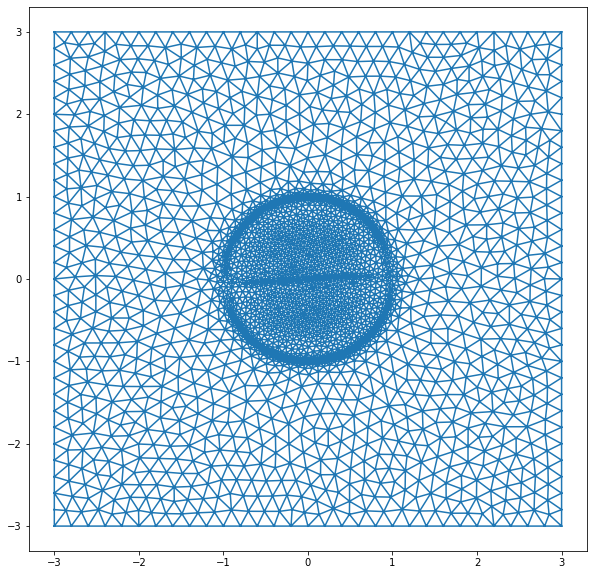

In [20]:
fig,ax = plt.subplots(figsize=(10,10))
ax.triplot(x[:,0], x[:,1], triangles);

In [15]:
len(triangles)

5948

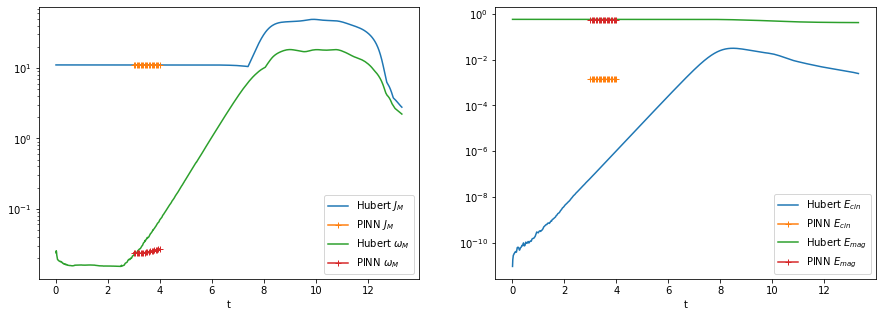

In [3]:
def plot_max_value(model):

    # spatial grid
    N = 120
    xspace = np.linspace(-3,3,N)
    yspace = np.linspace(-3,3,N)
    X, Y = np.meshgrid(xspace, yspace)
    
    omega_max = []
    J_max = []
    E_cin = []
    E_mag = []
    
    all_times = np.linspace(0.,1.,20)

    for t in all_times:

        tfinal = t * np.ones(N*N)
        Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
        Xgrid = tf.cast(Xgrid,DTYPE)
        
        tfinal, x, y = Xgrid[:,0:1], Xgrid[:,1:2], Xgrid[:,2:3]
        with tf.GradientTape(persistent=True) as tape:
            tape.watch(x)
            tape.watch(y)
        
            u = model(tf.stack([tfinal[:,0], x[:,0], y[:,0]], axis=1))
            omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]
            
            phi_x = tape.gradient(phi, x)
            phi_y = tape.gradient(phi, y)
            
            psi_x = tape.gradient(psi, x)
            psi_y = tape.gradient(psi, y)
                    
        E_cin.append( tf.reduce_mean(phi_x*phi_x + phi_y*phi_y)/2 )
        E_mag.append( tf.reduce_mean(psi_x*psi_x + psi_y*psi_y)/2 )
        del tape
        omega_max.append((tf.reduce_max(omega)-tf.reduce_min(omega))/2)
        J_max.append((tf.reduce_max(J)-tf.reduce_min(J))/2)
        
    data = np.genfromtxt (DATA_PATH+'histo.dat', delimiter=" ", skip_header=1)
        
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,5))
    axs = axs.flatten()
    
    all_times = [x+3. for x in all_times]
    axs[0].semilogy(data[:,0], data[:,1], '-', label=r'Hubert $J_M$')
    axs[0].semilogy(all_times, J_max, '+-', label=r'PINN $J_M$')
    axs[0].semilogy(data[:,0], data[:,3], '-', label=r'Hubert $\omega_M$')
    axs[0].semilogy(all_times, omega_max, '+-', label=r'PINN $\omega_M$')
    axs[0].set_xlabel('t')
    axs[0].set_ylabel('')
    axs[0].legend()
    
    axs[1].semilogy(data[:,0], data[:,4], '-', label=r'Hubert $E_{cin}$')
    axs[1].semilogy(all_times, E_cin, '+-', label=r'PINN $E_{cin}$')
    axs[1].semilogy(data[:,0], data[:,6], '-', label=r'Hubert $E_{mag}$')
    axs[1].semilogy(all_times, E_mag, '+-', label=r'PINN $E_{mag}$')
    axs[1].set_xlabel('t')
    axs[1].set_ylabel('')
    axs[1].legend()
    
    #plt.savefig(FIG_PATH+'wow', bbox_inches='tight', dpi=fig.dpi, facecolor='w', edgecolor='w', transparent=False)
    
plot_max_value(model)

# creer le gif

In [9]:
import imageio

In [10]:
filenames = []
for t in np.linspace(0,3.51,20):
    # plot the line chart
    N = 150

    # compute solution using PINN
    xspace = np.linspace(-3,3,N)
    yspace = np.linspace(-3,3,N)
    tfinal = t * np.ones(N*N)

    X, Y = np.meshgrid(xspace, yspace)
    Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
    u = model(tf.cast(Xgrid,DTYPE))

    omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]

    # reshape for plotting
    omega = omega.numpy().reshape(N,N)
    phi = phi.numpy().reshape(N,N)
    J = J.numpy().reshape(N,N)
    psi = psi.numpy().reshape(N,N)

    # affichage
    fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(9,6))

    # plot omega
    axs.set_xlabel('$x$')
    axs.set_ylabel('$y$')
    axs.set_aspect('equal')
    img0 = axs.imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
    cbar0 = plt.colorbar(img0, ax=axs)
    axs.set_title('t={:5.3}'.format(t))
    
    # create file name and append it to a list
    filename = f'{t*100}.png'
    filenames.append(filename)
    
    # save frame
    plt.savefig(FIG_PATH+filename)
    plt.close()# build gif
    
with imageio.get_writer('baseline.gif', mode='I') as writer:
    for filename in filenames:
        image = imageio.imread(FIG_PATH+filename)
        writer.append_data(image)
        